In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import csv
import random
#import g4ppyy as g4
#from g4ppyy.SI import mm, cm, m, eV, MeV, GeV, deg, twopi

In [13]:
fieldnames = ['radiation_number', 'incident_radiation_energy', 'energy_deposited', 'max_pen']

Alpha_dict = {key: [] for key in fieldnames}
Electron_dict = {key: [] for key in fieldnames}
Gamma_dict = {key: [] for key in fieldnames}
Neutron_dict = {key: [] for key in fieldnames}
Proton_dict = {key: [] for key in fieldnames}

with open('Data --- simulations/500keV/Alpha500keV.csv', newline='') as f:
    reader = csv.DictReader(f)
    for row in reader:
        Alpha_dict['radiation_number'].append(row['radiation_number'])
        Alpha_dict['incident_radiation_energy'].append(float(row['incident_radiation_energy']))
        Alpha_dict['energy_deposited'].append(float(row['energy_deposited']))
        Alpha_dict['max_pen'].append(row['max_pen'])

with open('Data --- simulations/500keV/Electron500keV.csv', newline='') as f:
    reader = csv.DictReader(f)
    for row in reader:
        Electron_dict['radiation_number'].append(row['radiation_number'])
        Electron_dict['incident_radiation_energy'].append(float(row['incident_radiation_energy']))
        Electron_dict['energy_deposited'].append(float(row['energy_deposited']))
        Electron_dict['max_pen'].append(row['max_pen'])

with open('Data --- simulations/500keV/Gamma500keV.csv', newline='') as f:
    reader = csv.DictReader(f)
    for row in reader:
        Gamma_dict['radiation_number'].append(row['radiation_number'])
        Gamma_dict['incident_radiation_energy'].append(float(row['incident_radiation_energy']))
        Gamma_dict['energy_deposited'].append(float(row['energy_deposited']))
        Gamma_dict['max_pen'].append(row['max_pen'])

with open('Data --- simulations/500keV/Neutron500keV.csv', newline='') as f:
    reader = csv.DictReader(f)
    for row in reader:
        Neutron_dict['radiation_number'].append(row['radiation_number'])
        Neutron_dict['incident_radiation_energy'].append(float(row['incident_radiation_energy']))
        Neutron_dict['energy_deposited'].append(float(row['energy_deposited']))
        Neutron_dict['max_pen'].append(row['max_pen'])

with open('Data --- simulations/500keV/Proton500keV.csv', newline='') as f:
    reader = csv.DictReader(f)
    for row in reader:
        Proton_dict['radiation_number'].append(row['radiation_number'])
        Proton_dict['incident_radiation_energy'].append(float(row['incident_radiation_energy']))
        Proton_dict['energy_deposited'].append(float(row['energy_deposited']))
        Proton_dict['max_pen'].append(row['max_pen'])

In [14]:
Alpha_df = pd.read_csv('Data --- simulations/500keV/Alpha500keVpanda.csv')
Electron_df = pd.read_csv('Data --- simulations/500keV/Electron500keVpanda.csv')
Gamma_df = pd.read_csv('Data --- simulations/500keV/Gamma500keVpanda.csv')
Neutron_df = pd.read_csv('Data --- simulations/500keV/Neutron500keVpanda.csv')
Proton_df = pd.read_csv('Data --- simulations/500keV/Proton500keVpanda.csv')

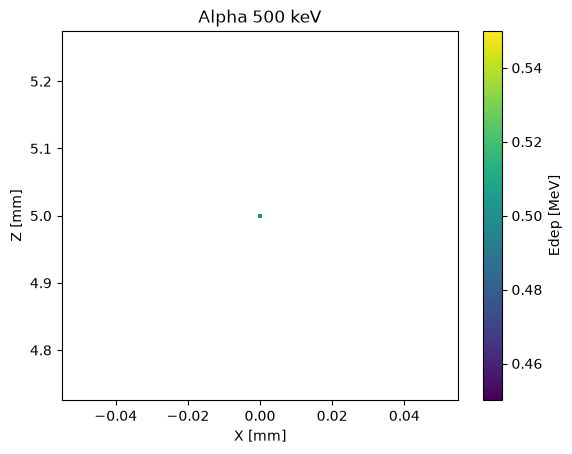

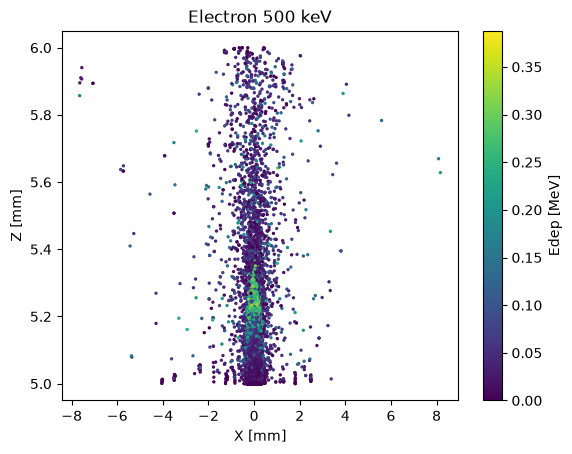

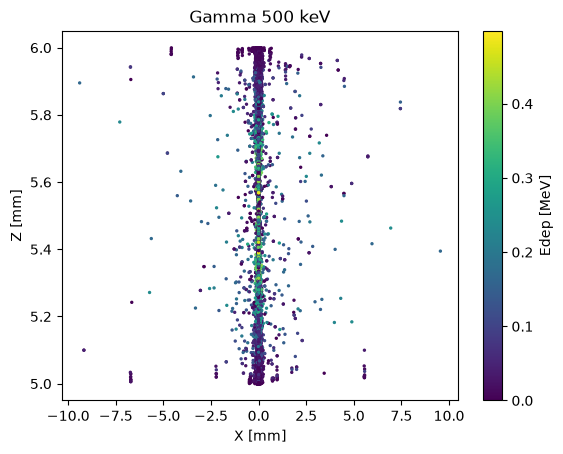

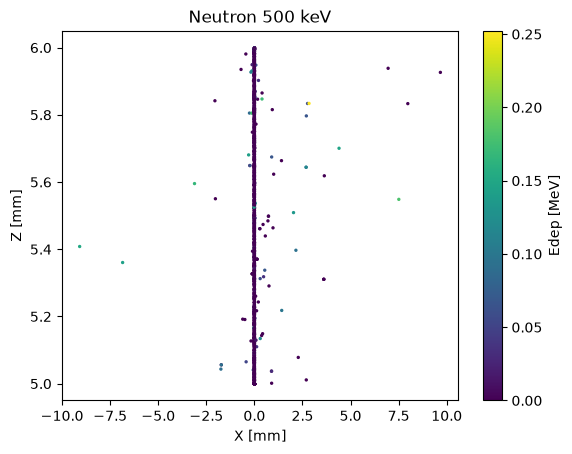

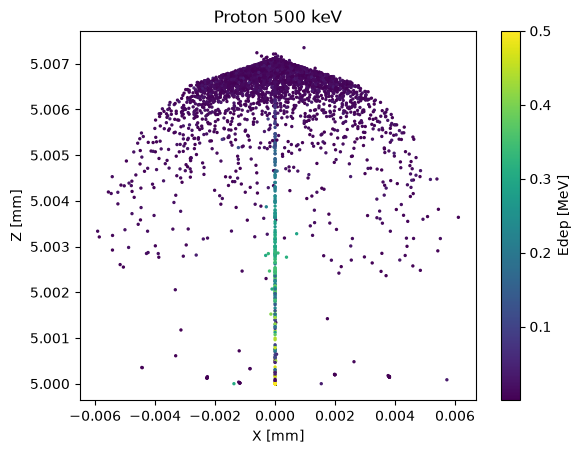

In [15]:
# plot energy depositions along the layer
for df in [Alpha_df, Electron_df, Gamma_df, Neutron_df, Proton_df]:
    plt.scatter(df.x, df.z, c=df.edep, s=2)
    width = 0.1
    #plt.xlim([-width,width])
    #plt.ylim([5.5,])
    plt.xlabel("X [mm]")
    plt.ylabel("Z [mm]")
    plt.colorbar(label="Edep [MeV]")

    if df is Alpha_df:
        plt.title("Alpha 500 keV")
    elif df is Electron_df:
        plt.title("Electron 500 keV")
    elif df is Gamma_df:
        plt.title("Gamma 500 keV")
    elif df is Neutron_df:
        plt.title("Neutron 500 keV")
    elif df is Proton_df:
        plt.title("Proton 500 keV")

    plt.show()

In [ ]:
number_events = 10000
for df in [Alpha_df, Electron_df, Gamma_df, Neutron_df, Proton_df]:    
# plot energy depositions along the layer
    #plt.scatter(df.gen_gamma_energy/mm, df.z/mm, s=1)
    #plt.xlabel("Original Radiation Energy[MeV]")
    #plt.ylabel("Z [mm]")
    #plt.show()

    plt.hist(df.z, bins=100)
    if df is Alpha_df:
        plt.title("Alpha 100 keV")
    elif df is Electron_df:
        plt.title("Electron 100 keV")
    elif df is Gamma_df:
        plt.title("Gamma 100 keV")
    elif df is Neutron_df:
        plt.title("Neutron 100 keV")
    elif df is Proton_df:
        plt.title("Proton 100 keV")
    plt.xlabel("Z (mm)")
    plt.ylabel("Counts")
    plt.show()

    #plt.hist(df.gen_gamma_energy, bins=100)
    #plt.xlabel("Original Radiation Energy (MeV)")
    #plt.ylabel("Counts")
    #plt.show()


    #plt.hist(df.groupby('eid')['edep'].sum(), bins=100)#bins=np.linspace(0.0001,1,100))
    #plt.xlabel("Energy deposited within the perovskite (MeV)")
    #plt.ylabel("Counts")
    #plt.show()

    print(f"Number of Radiation (out of {number_events}) that interacted at least once is {np.sum(df.groupby('eid')['edep'].sum() > 0)}")
    print(f"This implies a {100 * np.sum(df.groupby('eid')['edep'].sum() > 0)/number_events}% of particles interacted with the material.")

    total_incident_energy = np.sum(df.gen_gamma_energy)
    total_energy_absorbed = np.sum(df.groupby('eid')['edep'].sum())

    print(f"Total energy started was {total_incident_energy}.")
    print(f"Total energy absorbed was {total_energy_absorbed}.")
    print(f"percentage energy absorbed was {100 * total_energy_absorbed/total_incident_energy}%")